# Final model

Our final net for Project 1, with its test result, confusion matrix and new digits test. **You don't need to run anything, because every result is saved below.**

| Result | Value |
|---|---:|
| Test accuracy | 99.34% (66 errors in 10,000) |
| Mean on 50,000 new digits | 99.23% |
| Weights | 20,638 |
| Training time | About 82 s on a T4 GPU |

The net was trained once in Colab. This notebook loads that saved net instead of training again, because runs are not exactly repeatable. The training log is copied from that Colab run. All other outputs came from running the saved net on a PC, with no training.

## 1. Settings

The main settings, all in one place. `SLICES` sets the size of the net, and `TRAIN` decides whether section 7 trains a new net or loads the saved one.

In [1]:
TRAIN      = False      # False loads the saved final net.  True trains a new net, which
                        # takes about 82 s on a T4 GPU and will not match exactly.

EPOCHS     = 20         # Training run parameters.  Every run takes all 20 epochs.
SPLIT      = 0.2        # 80%/20% train/val split.
SHUFFLE    = True       # Shuffle training data before each epoch.
BATCH      = 64         # Minibatch size (note Keras default is 32).
RATE       = 0.002      # Starting learning rate, falls to 0 along a cosine curve.

SLICES     = 12         # Slices in the first layer.  This one number sets the size
                        # of the net.  Chosen by the second search.
DROPOUT    = 0.1        # Fraction of outputs dropped after each maxpool.  This and
                        # EPOCHS were chosen by the third search.

## 2. Imports and random seed

Loads the libraries and sets the random seed. The GPU list is empty here because this notebook was last run on a PC. The real training ran on a T4 GPU in Colab.

In [2]:
import os

import numpy as np
import matplotlib.pyplot as plt


# Initialise the random number generators to help reduce variance
# between runs.  Can't eliminate it completely, but this initialisation
# is of some use.
#
import tensorflow
from tensorflow.keras.utils import set_random_seed

set_random_seed(1)                   # Seeds Python, NumPy and the Tensorflow backend, as in the search.


VERSION = tensorflow.__version__
print(VERSION)                       # Should be at least 2.0.
print(tensorflow.config.list_physical_devices('GPU')) # An empty list means no GPU.
NEW_KERAS = True if int(VERSION.split('.')[1]) > 12 else False # If tf > 2.12 use InputLayer.


# Import the relevant Keras library modules.

from tensorflow.keras.models import Sequential, load_model
from tensorflow.keras.layers import Dense                    # Fully-connected layer
if NEW_KERAS: from tensorflow.keras.layers import InputLayer # InputLayer if using a modern (> 2.12) Keras
from tensorflow.keras.layers import Conv2D                   # 2-d Convolutional layer
from tensorflow.keras.layers import MaxPooling2D             # 2-d Max-pooling layer
from tensorflow.keras.layers import GlobalAveragePooling2D   # Averages each slice down to one number
from tensorflow.keras.layers import BatchNormalization       # Rescales the inputs to the next layer
from tensorflow.keras.layers import Activation               # Nonlinearities
from tensorflow.keras.layers import Dropout                  # Regularisation, training only, adds no weights

from tensorflow.keras.optimizers import RMSprop
from tensorflow.keras.optimizers.schedules import CosineDecay
from tensorflow.keras.utils import to_categorical
from tensorflow.keras.callbacks import EarlyStopping
from tensorflow.keras.datasets import mnist

2.21.0


[]


## 3. Load the data

MNIST has 60,000 training images and 10,000 test images, each 28 × 28 pixels. Keras downloads them on first use.

In [3]:
# Load up the MNIST dataset.  It will be downloaded automatically from the
# repository on first use.
#
# There are 60000 28 x 28 8-bit greyscale training images and 10000 test
# images.

(training_inputs, training_labels), (testing_inputs, testing_labels) = mnist.load_data()

print(training_inputs.shape, training_inputs.dtype, testing_inputs.shape, testing_inputs.dtype)

(60000, 28, 28) uint8 (10000, 28, 28) uint8


## 4. Prepare the data

Scales the pixels to between 0 and 1, and reshapes the images for the convolutional layers. The labels become categorical vectors of 10 values.

In [4]:
# The inputs to the network need to be normalised 'float32' values, in a
# tensor of shape (N,28,28,1), as the Keras "Conv2D" layer expects 4-tensors.
# The labels also need to be converted to categorical form.

training_images = (training_inputs.astype('float32')/255)[:,:,:,np.newaxis]  # Normalised float32 4-tensor.

categorical_training_outputs = to_categorical(training_labels)

testing_images = (testing_inputs.astype('float32')/255)[:,:,:,np.newaxis]

categorical_testing_outputs = to_categorical(testing_labels)

print(training_images.shape,training_images.dtype)
print(testing_images.shape,testing_images.dtype)
print(categorical_training_outputs.shape, training_labels.shape)
print(categorical_testing_outputs.shape, testing_labels.shape)

(60000, 28, 28, 1) float32
(10000, 28, 28, 1) float32
(60000, 10) (60000,)
(10000, 10) (10000,)


## 5. Build the net

Five convolutional layers, each followed by Batch Normalisation and ReLU, with a maxpool and Dropout after every second layer. Global Average Pooling replaces the large Flatten and Dense layers, and that swap saved the most weights. The table shows 20,638 weights in total.

In [5]:
# Create a Keras model for a net.
#
# Two stacked 3 x 3 layers see the same 5 x 5 patch of their input as a single
# 5 x 5 layer, but with fewer weights and an extra nonlinearity.
#
# Each maxpool halves the image size (28 x 28 --> 14 x 14 --> 7 x 7), and the
# number of slices doubles to compensate.
#
# Dropout randomly disables a fraction of its inputs on each training step,
# which stops the net relying too heavily on any one feature.  It adds no
# weights and is only active during training.  In the search it replaced
# random rotations and shifts with no loss of accuracy, at half the time per
# epoch.
#
# Batch Normalisation rescales the outputs of each convolutional layer, which
# lets a small net train quickly and reliably.
#
# Global Average Pooling then reduces each of the final 7 x 7 slices to its
# average value.  The output layer is left with 4S inputs, where Flatten would
# have given it 7 x 7 x 4S.  There is no hidden Dense layer.
#
in_shape = training_images.shape[1:]   # Returns a 3-tuple (rows,cols,channels), the shape of the input images.

model = Sequential()

if NEW_KERAS:
    model.add(InputLayer(shape=in_shape))
    model.add(Conv2D(SLICES, kernel_size=3, padding='same'))
else:
    model.add(Conv2D(SLICES, kernel_size=3, padding='same', input_shape=in_shape))

model.add(BatchNormalization())
model.add(Activation('relu'))
model.add(Conv2D(SLICES, kernel_size=3, padding='same'))
model.add(BatchNormalization())
model.add(Activation('relu'))
model.add(MaxPooling2D(pool_size=(2,2), strides=(2,2)))
model.add(Dropout(DROPOUT))

model.add(Conv2D(2*SLICES, kernel_size=3, padding='same'))
model.add(BatchNormalization())
model.add(Activation('relu'))
model.add(Conv2D(2*SLICES, kernel_size=3, padding='same'))
model.add(BatchNormalization())
model.add(Activation('relu'))
model.add(MaxPooling2D(pool_size=(2,2), strides=(2,2)))
model.add(Dropout(DROPOUT))

model.add(Conv2D(4*SLICES, kernel_size=3, padding='same'))
model.add(BatchNormalization())
model.add(Activation('relu'))

model.add(GlobalAveragePooling2D())
model.add(Dense(10))
model.add(Activation('softmax'))


# Review the network, to make sure that Keras has the same ideas that we do.

print("The Keras network model")
model.summary()

The Keras network model


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 28, 28, 12)     │           120 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 28, 28, 12)     │            48 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation (Activation)         │ (None, 28, 28, 12)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 28, 28, 12)     │         1,308 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 28, 28, 12)     │            48 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_1 (Activation)       │ (None, 28, 28, 12)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 14, 14, 12)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 14, 14, 12)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 14, 14, 24)     │         2,616 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 14, 14, 24)     │            96 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_2 (Activation)       │ (None, 14, 14, 24)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 14, 14, 24)     │         5,208 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 14, 14, 24)     │            96 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_3 (Activation)       │ (None, 14, 14, 24)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 7, 7, 24)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 7, 7, 24)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 7, 7, 48)       │        10,416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_4           │ (None, 7, 7, 48)       │           192 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_4 (Activation)       │ (None, 7, 7, 48)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 48)             │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 10)             │           490 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_5 (Activation)       │ (None, 10)             │             

 Total params: 20,638 (80.62 KB)

 Trainable params: 20,398 (79.68 KB)

 Non-trainable params: 240 (960.00 B)

## 6. Set up training

Sets the loss and the RMSprop optimiser. The learning rate starts at 0.002 and falls to 0 along a cosine curve over the full run.

In [6]:
# Compile, Log-Loss ("categorical_crossentropy") with an adaptive gradient
# algorithm, monitoring accuracy as well as loss.
#
# The learning rate starts at RATE and falls smoothly to 0 over the full run.
# A high rate makes quick progress early on but then bounces around the
# minimum, so a falling rate lets the net settle into it.  The curve is fixed
# in advance, so a noisy validation loss cannot cut the rate too early.

steps = EPOCHS*int(np.ceil(len(training_images)*(1-SPLIT)/BATCH))  # Training batches in the full run.
schedule = CosineDecay(RATE, decay_steps=steps)

model.compile(loss='categorical_crossentropy', optimizer=RMSprop(learning_rate=schedule), metrics=['accuracy'])

## 7. Train, or load the saved net

With `TRAIN = False`, this loads the saved final net, so pressing Run All can't retrain it. To run this yourself, keep `kerasMNIST_CNN.keras` in the same folder as this notebook.

With `TRAIN = True`, it trains a new net and saves it as `kerasMNIST_CNN_retrained.keras`, so the final net is never overwritten. Either way, the weights kept are those from the epoch with the highest validation accuracy.

In [7]:
# Now we are ready to train.  Patience equal to the epoch limit means that
# EarlyStopping never halts the run.  It is only used to restore the weights
# from the epoch with the highest validation accuracy at the end.
#

best_weights = EarlyStopping(monitor='val_accuracy', min_delta=0, patience=EPOCHS,
                             verbose=2, mode='max',
                             restore_best_weights=True)

if TRAIN:
    history = model.fit(training_images, categorical_training_outputs,
                        epochs=EPOCHS,
                        batch_size=BATCH,
                        shuffle=SHUFFLE,
                        validation_split=SPLIT,
                        verbose=2,
                        callbacks=[best_weights])
    model.save('kerasMNIST_CNN_retrained.keras')   # A new name, so the final net is never overwritten.
else:
    model = load_model('kerasMNIST_CNN.keras')
    print("Loaded the saved final net, with no training.")
    print("Weights: {:,}".format(model.count_params()))

Loaded the saved final net, with no training.
Weights: 20,638


### Log from the final training run

Copied from the Colab run that produced the saved net. The best epoch was 16 of 20, and training took about 82 s on a T4 GPU.

```text
Epoch 1/20
750/750 - 11s - 15ms/step - accuracy: 0.9281 - loss: 0.2992 - val_accuracy: 0.9672 - val_loss: 0.1055
Epoch 2/20
750/750 - 4s - 5ms/step - accuracy: 0.9779 - loss: 0.0738 - val_accuracy: 0.9508 - val_loss: 0.1568
Epoch 3/20
750/750 - 5s - 6ms/step - accuracy: 0.9823 - loss: 0.0562 - val_accuracy: 0.9758 - val_loss: 0.0749
Epoch 4/20
750/750 - 3s - 5ms/step - accuracy: 0.9847 - loss: 0.0482 - val_accuracy: 0.9879 - val_loss: 0.0385
Epoch 5/20
750/750 - 4s - 5ms/step - accuracy: 0.9873 - loss: 0.0421 - val_accuracy: 0.9828 - val_loss: 0.0571
Epoch 6/20
750/750 - 3s - 5ms/step - accuracy: 0.9880 - loss: 0.0376 - val_accuracy: 0.9822 - val_loss: 0.0508
Epoch 7/20
750/750 - 3s - 5ms/step - accuracy: 0.9900 - loss: 0.0321 - val_accuracy: 0.9897 - val_loss: 0.0337
Epoch 8/20
750/750 - 3s - 5ms/step - accuracy: 0.9910 - loss: 0.0282 - val_accuracy: 0.9892 - val_loss: 0.0336
Epoch 9/20
750/750 - 4s - 5ms/step - accuracy: 0.9908 - loss: 0.0269 - val_accuracy: 0.9894 - val_loss: 0.0297
Epoch 10/20
750/750 - 3s - 4ms/step - accuracy: 0.9926 - loss: 0.0232 - val_accuracy: 0.9908 - val_loss: 0.0273
Epoch 11/20
750/750 - 4s - 6ms/step - accuracy: 0.9927 - loss: 0.0222 - val_accuracy: 0.9926 - val_loss: 0.0244
Epoch 12/20
750/750 - 4s - 5ms/step - accuracy: 0.9947 - loss: 0.0177 - val_accuracy: 0.9920 - val_loss: 0.0245
Epoch 13/20
750/750 - 3s - 5ms/step - accuracy: 0.9944 - loss: 0.0174 - val_accuracy: 0.9927 - val_loss: 0.0256
Epoch 14/20
750/750 - 5s - 7ms/step - accuracy: 0.9950 - loss: 0.0155 - val_accuracy: 0.9933 - val_loss: 0.0240
Epoch 15/20
750/750 - 4s - 5ms/step - accuracy: 0.9952 - loss: 0.0143 - val_accuracy: 0.9936 - val_loss: 0.0211
Epoch 16/20
750/750 - 3s - 5ms/step - accuracy: 0.9955 - loss: 0.0138 - val_accuracy: 0.9942 - val_loss: 0.0211
Epoch 17/20
750/750 - 3s - 4ms/step - accuracy: 0.9962 - loss: 0.0127 - val_accuracy: 0.9942 - val_loss: 0.0219
Epoch 18/20
750/750 - 4s - 5ms/step - accuracy: 0.9965 - loss: 0.0122 - val_accuracy: 0.9939 - val_loss: 0.0214
Epoch 19/20
750/750 - 6s - 8ms/step - accuracy: 0.9967 - loss: 0.0109 - val_accuracy: 0.9940 - val_loss: 0.0213
Epoch 20/20
750/750 - 3s - 4ms/step - accuracy: 0.9965 - loss: 0.0116 - val_accuracy: 0.9940 - val_loss: 0.0213
Restoring model weights from the end of the best epoch: 16.
Performance of network on testing set:
313/313 - 2s - 7ms/step - accuracy: 0.9934 - loss: 0.0188
Accuracy on testing data:  99.34%
Test error (loss):          0.0188
Performance of network (best epoch was 16):
Accuracy on training data:    99.55%
Accuracy on validation data:  99.42%
Accuracy on testing data:     99.34%
```

## 8. Training plots

Accuracy and loss for each epoch of the final run. These are the same pictures as in `figures/`.

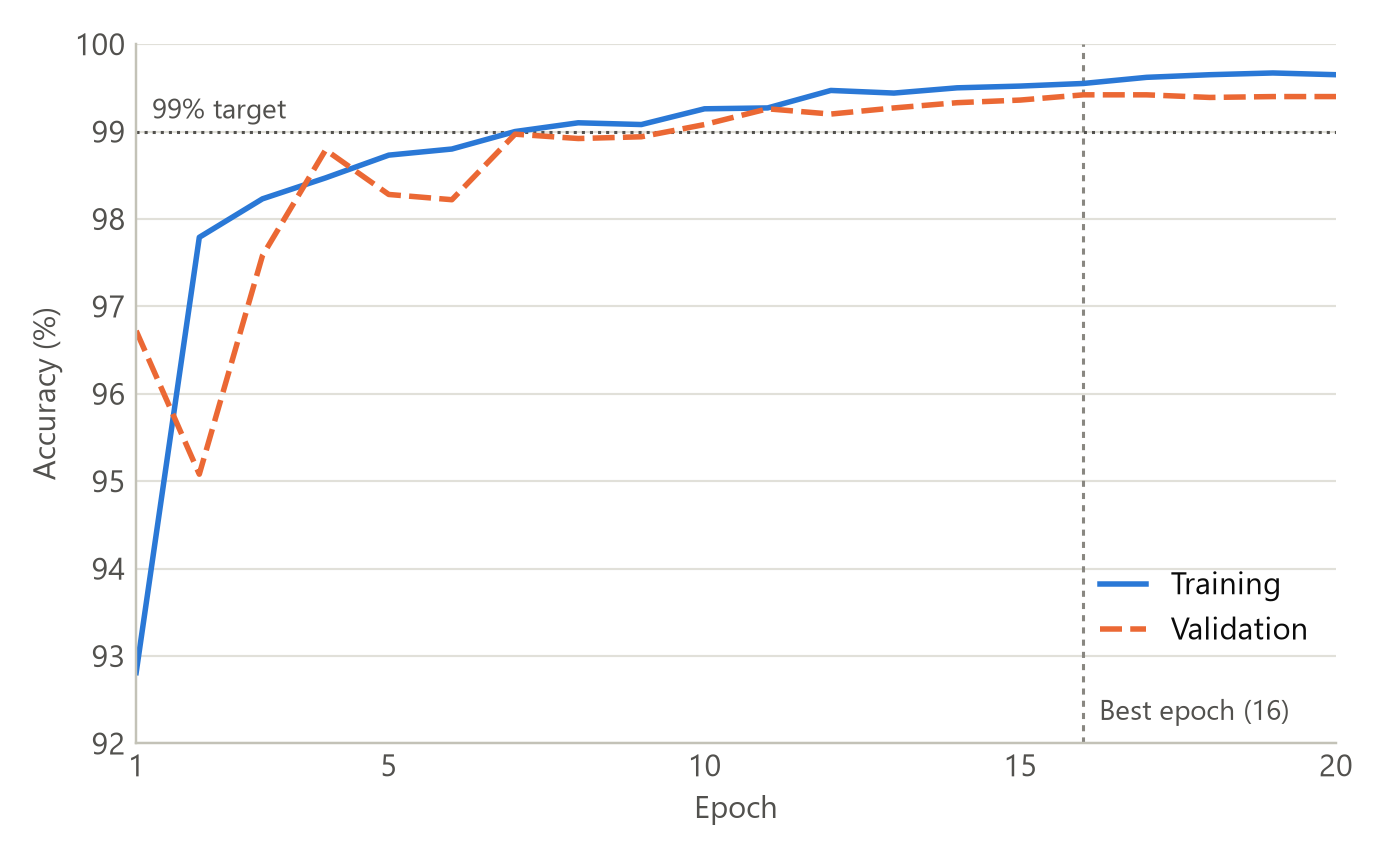

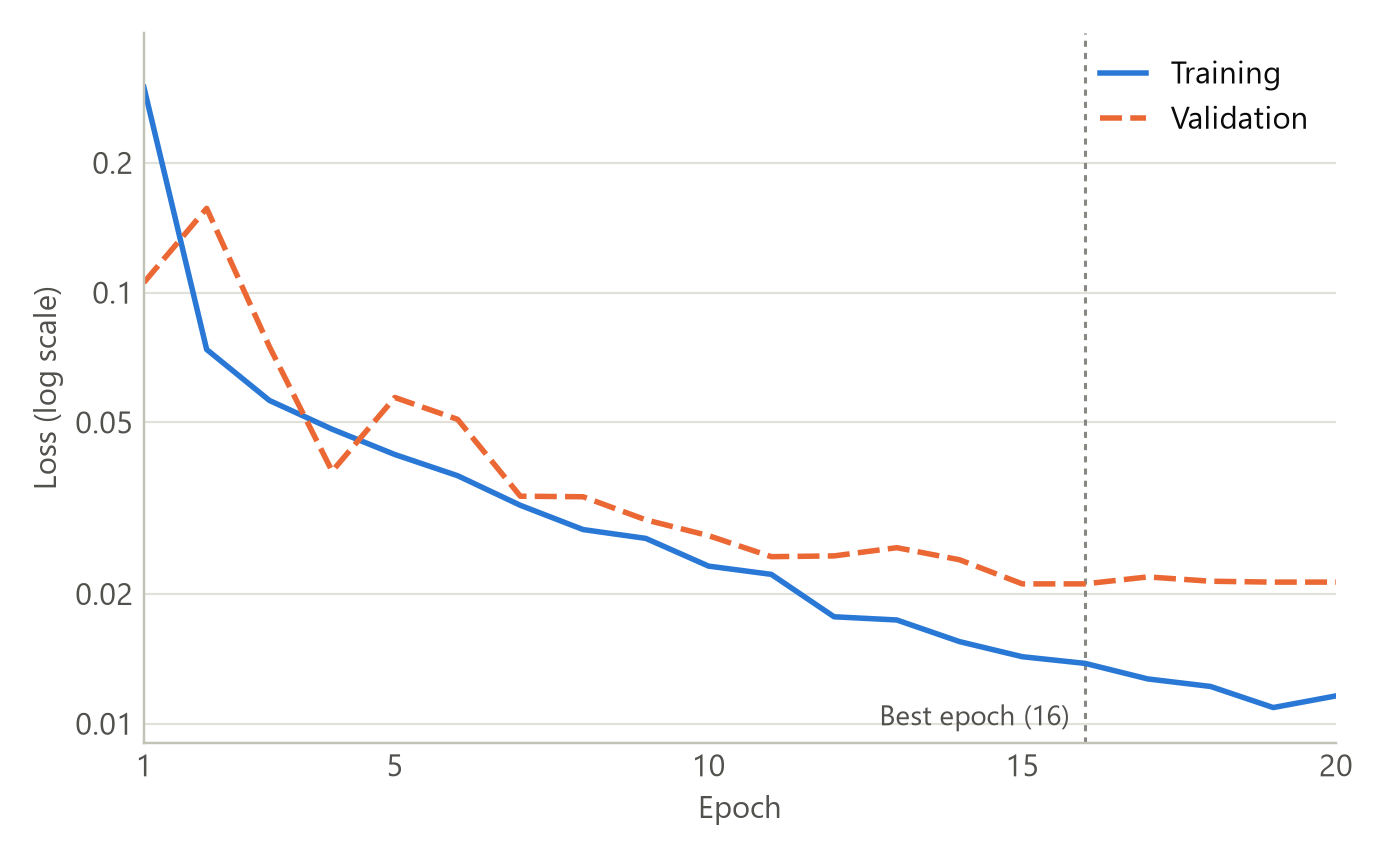

In [8]:
from IPython.display import Image, display

# The saved run has no history to plot, so this shows its plots from figures/.

if TRAIN:
    # We can now examine the loss (error) per epoch for both the training
    # and the validation data.

    plt.figure('Training and Validation Losses per epoch', figsize=(8,8))

    plt.plot(history.history['loss'],label='training') # Training data error per epoch.

    plt.plot(history.history['val_loss'],label='validation') # Validation error per ep.

    plt.grid(True)

    plt.legend()

    plt.xlabel('Epoch Number')
    plt.ylabel('Loss')



    # And the same for the accuracy per epoch.

    plt.figure('Training and Validation Accuracy per epoch', figsize=(8,8))

    plt.plot(history.history['accuracy'],label='training') # Training data accuracy per epoch.

    plt.plot(history.history['val_accuracy'],label='validation') # Validation accuracy per ep.

    plt.grid(True)

    plt.legend()

    plt.xlabel('Epoch Number')
    plt.ylabel('Accuracy')

    plt.show()
else:
    for path in ['../figures/3.1_accuracy.png', '../figures/3.2_loss.png']:
        if os.path.exists(path):
            display(Image(path, width=560))

## 9. Test set result

Measures the net on the 10,000 MNIST test images. This should give the project's result of 99.34%.

In [9]:
# Performance on the completely separate testing set.  This is testing on
# unseen inputs, so is a true measure of performance.

print("Performance of network on testing set:")
test_loss,test_acc = model.evaluate(testing_images,categorical_testing_outputs, verbose=2) # Verbose=2 to avoid progress bar bug, 2025/06/17.
print("Accuracy on testing data: {:6.2f}%".format(test_acc*100))
print("Test error (loss):        {:8.4f}".format(test_loss))


# Report the training and validation figures from the best epoch, which is
# the one whose weights were restored by early stopping.  The training
# accuracy is measured with Dropout active, so it understates what the net
# can do and may be lower than the validation accuracy.

if TRAIN:
    best = int(np.argmax(history.history['val_accuracy']))

    print("Performance of network (best epoch was {}):".format(best+1))
    print("Accuracy on training data:   {:6.2f}%".format(history.history['accuracy'][best]*100))
    print("Accuracy on validation data: {:6.2f}%".format(history.history['val_accuracy'][best]*100))
    print("Accuracy on testing data:    {:6.2f}%".format(test_acc*100))

Performance of network on testing set:


313/313 - 3s - 9ms/step - accuracy: 0.9934 - loss: 0.0188


Accuracy on testing data:  99.34%
Test error (loss):          0.0188


## 10. Confusion matrix

Each image adds one to the cell at row (predicted digit), column (true digit), so correct predictions sit on the diagonal. The first line should say 9934 correct.

In [10]:
# The responses are a 10000 x 10 matrix, one row of ten outputs per image.

responses = model.predict(testing_images, verbose=2)
predicted_labels = np.argmax(responses, axis=1)

confusion = np.zeros((10,10), dtype=int)

for predicted, true in zip(predicted_labels, testing_labels):
    confusion[predicted, true] += 1


# Should match the accuracy printed by kerasMNIST_CNN.py.

correct = np.trace(confusion)
print("Correct: {} of {} ({:.2f}%)".format(correct, confusion.sum(), 100*correct/confusion.sum()))

print("Confusion matrix (rows = predicted label, columns = true label):")
print("      " + "".join("{:6d}".format(digit) for digit in range(10)))
for digit in range(10):
    print("{:6d}".format(digit) + "".join("{:6d}".format(count) for count in confusion[digit]))

313/313 - 2s - 7ms/step


Correct: 9934 of 10000 (99.34%)
Confusion matrix (rows = predicted label, columns = true label):
           0     1     2     3     4     5     6     7     8     9
     0   976     0     2     0     0     1     4     0     0     2
     1     0  1133     1     0     0     0     3     3     0     0
     2     0     1  1023     0     0     0     1     3     0     2
     3     0     0     1  1008     0     5     0     1     1     0
     4     0     1     1     0   979     0     0     0     0     8
     5     1     0     0     1     0   885     2     0     0     3
     6     1     0     0     0     0     1   946     0     0     0
     7     1     0     3     0     1     0     0  1021     1     1
     8     0     0     1     1     1     0     1     0   971     1
     9     1     0     0     0     1     0     1     0     1   992


The most common mistakes, and the accuracy on each digit.

In [11]:
# The errors alone, largest first, and the accuracy on each digit.

errors = confusion - np.diag(np.diag(confusion))
print("Most common errors:")
for index in np.argsort(errors, axis=None)[::-1][:5]:
    predicted, true = np.unravel_index(index, errors.shape)
    print("  true {} predicted as {}: {} times".format(true, predicted, errors[predicted, true]))

print("Accuracy on each digit:")
for digit in range(10):
    print("  {}: {:6.2f}%".format(digit, 100*confusion[digit, digit]/confusion[:, digit].sum()))

Most common errors:
  true 9 predicted as 4: 8 times
  true 5 predicted as 3: 5 times
  true 6 predicted as 0: 4 times
  true 2 predicted as 7: 3 times
  true 9 predicted as 5: 3 times
Accuracy on each digit:
  0:  99.59%
  1:  99.82%
  2:  99.13%
  3:  99.80%
  4:  99.69%
  5:  99.22%
  6:  98.75%
  7:  99.32%
  8:  99.69%
  9:  98.32%


## 11. New digits test

MNIST has no unused images, so this uses QMNIST (Yadav and Bottou, 2019), which rebuilds 50,000 test digits that were left out of the MNIST release. None of these digits or their writers are in our training data. The files download once, to a Keras folder outside this repo.

In [12]:
import gzip

from tensorflow.keras.utils import get_file

GROUPS  = 5
ORIGIN  = 'https://raw.githubusercontent.com/facebookresearch/qmnist/master/'
IMAGES  = 'qmnist-test-images-idx3-ubyte.gz'
LABELS  = 'qmnist-test-labels-idx2-int.gz'
IMAGES_HASH = '43fc22bf7498b8fc98de98369d72f752d0deabc280a43a7bcc364ab19e57b375'
LABELS_HASH = '9fbcbe594c3766fdf4f0b15c5165dc0d1e57ac604e01422608bb72c906030d06'


# Downloaded once, then kept in a Keras folder outside the project.  The hash
# confirms that the file is the one these results came from.

def read_file(name, file_hash, header_bytes, data_type):
    path = get_file(name, origin=ORIGIN+name, file_hash=file_hash, cache_subdir='qmnist')
    with gzip.open(path, 'rb') as contents:
        return np.frombuffer(contents.read()[header_bytes:], dtype=data_type)


# Each row of the labels has 8 columns.  Column 0 is the digit, and column 1 is
# the NIST series: 4 is high school students, and 0 and 1 are Census employees.

qmnist_inputs = read_file(IMAGES, IMAGES_HASH, 16, 'u1').reshape(-1,28,28)
qmnist_labels = read_file(LABELS, LABELS_HASH, 12, '>i4').reshape(-1,8)

### Two checks first

The saved net should give 99.34% on the MNIST test set, and about the same on QMNIST's rebuilt copy of those images. That shows the rebuilding barely changes the score.

In [13]:
def predict(inputs):
    images = (inputs.astype('float32')/255)[:,:,:,np.newaxis]
    return np.argmax(model.predict(images, batch_size=256, verbose=2), axis=1)


predicted_labels = predict(qmnist_inputs)
correct = predicted_labels == qmnist_labels[:,0]


# Two checks first.  The first should give the project's 99.34%.  The second is
# QMNIST's rebuilt copy of those same digits, which shows if the rebuilding
# changes the score.

mnist_score = 100*np.mean(predict(testing_inputs) == testing_labels)
matching = np.mean(qmnist_labels[:10000,0] == testing_labels)

print("MNIST test set:             {:6.2f}%".format(mnist_score))
print("QMNIST copy of that set:    {:6.2f}%  ({:.2f}% of labels match)".format(
      100*np.mean(correct[:10000]), 100*matching))

235/235 - 4s - 19ms/step


40/40 - 1s - 17ms/step


MNIST test set:              99.34%
QMNIST copy of that set:     99.35%  (100.00% of labels match)


### The mean on new digits

The 50,000 new digits are taken in file order as 5 groups of 10,000, the same size as the MNIST test set. The spread between the groups shows how much a score of this size moves by chance. 99.34% stays the project's test result.

In [14]:
# The new digits.

new_correct = correct[10000:]
new_labels = qmnist_labels[10000:,0]
new_predicted = predicted_labels[10000:]
new_series = qmnist_labels[10000:,1]

scores = [100*np.mean(group) for group in np.split(new_correct, GROUPS)]

print("New digits, {} groups of {}:".format(GROUPS, len(new_correct)//GROUPS))
for number, score in enumerate(scores, start=1):
    print("  group {}: {:6.2f}%".format(number, score))

fraction = np.mean(new_correct)
margin = 196*np.sqrt(fraction*(1-fraction)/len(new_correct))

print("Mean of the groups:         {:6.2f}%".format(np.mean(scores)))
print("Standard deviation:         {:6.2f} points".format(np.std(scores, ddof=1)))
print("Lowest and highest group:   {:6.2f}% and {:.2f}%".format(min(scores), max(scores)))
print("All new digits:             {:6.2f}%  ({} errors of {}, 95% interval {:.2f}% to {:.2f}%)".format(
      100*fraction, np.sum(~new_correct), len(new_correct), 100*fraction-margin, 100*fraction+margin))

New digits, 5 groups of 10000:
  group 1:  99.17%
  group 2:  99.27%
  group 3:  99.23%
  group 4:  99.21%
  group 5:  99.29%
Mean of the groups:          99.23%
Standard deviation:           0.05 points
Lowest and highest group:    99.17% and 99.29%
All new digits:              99.23%  (383 errors of 50000, 95% interval 99.16% to 99.31%)


### Where the errors fall

Scores by writer group, accuracy on each digit and the most common errors. With this many digits, these figures are steadier than those from the 10,000 test images.

In [15]:
# Where the errors fall.  Rows of the confusion matrix are the predicted label,
# and columns the true label, as in kerasMNIST_CNN_confusion.py.

print("By source:")
students = new_series == 4
print("  High school students: {:6.2f}%  ({} digits)".format(100*np.mean(new_correct[students]), np.sum(students)))
print("  Census employees:     {:6.2f}%  ({} digits)".format(100*np.mean(new_correct[~students]), np.sum(~students)))

confusion = np.zeros((10,10), dtype=int)

for predicted, true in zip(new_predicted, new_labels):
    confusion[predicted, true] += 1

print("Accuracy on each digit:")
for digit in range(10):
    print("  {}: {:6.2f}%".format(digit, 100*confusion[digit, digit]/confusion[:, digit].sum()))

errors = confusion - np.diag(np.diag(confusion))
print("Most common errors:")
for index in np.argsort(errors, axis=None)[::-1][:5]:
    predicted, true = np.unravel_index(index, errors.shape)
    print("  true {} predicted as {}: {} times".format(true, predicted, errors[predicted, true]))

By source:
  High school students:  98.96%  (24594 digits)
  Census employees:      99.50%  (25406 digits)
Accuracy on each digit:
  0:  99.56%
  1:  99.72%
  2:  98.96%
  3:  99.25%
  4:  99.19%
  5:  99.12%
  6:  99.38%
  7:  99.14%
  8:  99.21%
  9:  98.74%
Most common errors:
  true 4 predicted as 9: 22 times
  true 9 predicted as 4: 18 times
  true 7 predicted as 4: 15 times
  true 2 predicted as 8: 14 times
  true 3 predicted as 5: 14 times
